# Assignment 2

In this assigment, we will work with the *Forest Fire* data set. Please download the data from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/162/forest+fires). Extract the data files into the subdirectory: `../data/fires/` (relative to `./05_src/`).

## Objective

+ The model objective is to predict the area affected by forest fires given the features set. 
+ The objective of this exercise is to assess your ability to construct and evaluate model pipelines.
+ Please note: the instructions are not meant to be 100% prescriptive, but instead they are a set of minimum requirements. If you find predictive performance gains by applying additional steps, by all means show them. 

## Variable Description

From the description file contained in the archive (`forestfires.names`), we obtain the following variable descriptions:

1. X - x-axis spatial coordinate within the Montesinho park map: 1 to 9
2. Y - y-axis spatial coordinate within the Montesinho park map: 2 to 9
3. month - month of the year: "jan" to "dec" 
4. day - day of the week: "mon" to "sun"
5. FFMC - FFMC index from the FWI system: 18.7 to 96.20
6. DMC - DMC index from the FWI system: 1.1 to 291.3 
7. DC - DC index from the FWI system: 7.9 to 860.6 
8. ISI - ISI index from the FWI system: 0.0 to 56.10
9. temp - temperature in Celsius degrees: 2.2 to 33.30
10. RH - relative humidity in %: 15.0 to 100
11. wind - wind speed in km/h: 0.40 to 9.40 
12. rain - outside rain in mm/m2 : 0.0 to 6.4 
13. area - the burned area of the forest (in ha): 0.00 to 1090.84 









### Specific Tasks

+ Construct four model pipelines, out of combinations of the following components:

    + Preprocessors:

        - A simple processor that only scales numeric variables and recodes categorical variables.
        - A transformation preprocessor that scales numeric variables and applies a non-linear transformation.
    
    + Regressor:

        - A baseline regressor, which could be a [K-nearest neighbours model]() or a linear model like [Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html) or [Ridge Regressors](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ridge_regression.html).
        - An advanced regressor of your choice (e.g., Bagging, Boosting, SVR, etc.). TIP: select a tree-based method such that it does not take too long to run SHAP further below. 

+ Evaluate tune and evaluate each of the four model pipelines. 

    - Select a [performance metric](https://scikit-learn.org/stable/modules/linear_model.html) out of the following options: explained variance, max error, root mean squared error (RMSE), mean absolute error (MAE), r-squared.
    - *TIPS*: 
    
        * Out of the suggested metrics above, [some are correlation metrics, but this is a prediction problem](https://www.tmwr.org/performance#performance). Choose wisely (and don't choose the incorrect options.) 

+ Select the best-performing model and explain its predictions.

    - Provide local explanations.
    - Obtain global explanations and recommend a variable selection strategy.

+ Export your model as a pickle file.


You can work on the Jupyter notebook, as this experiment is fairly short (no need to use sacred). 

# Load the data

Place the files in the ../../05_src/data/fires/ directory and load the appropriate file. 

In [1]:
# Load the libraries as required.
import os
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

d:\sourcecodeforUofTDSI\MachineLearningFoundations2\production\production-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load data
columns = [
    'coord_x', 'coord_y', 'month', 'day', 'ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain', 'area' 
]
fires_dt = (pd.read_csv('../../05_src/data/fires/forestfires.csv', header = 0, names = columns))
fires_dt.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   coord_x  517 non-null    int64  
 1   coord_y  517 non-null    int64  
 2   month    517 non-null    object 
 3   day      517 non-null    object 
 4   ffmc     517 non-null    float64
 5   dmc      517 non-null    float64
 6   dc       517 non-null    float64
 7   isi      517 non-null    float64
 8   temp     517 non-null    float64
 9   rh       517 non-null    int64  
 10  wind     517 non-null    float64
 11  rain     517 non-null    float64
 12  area     517 non-null    float64
dtypes: float64(8), int64(3), object(2)
memory usage: 52.6+ KB


# Get X and Y

Create the features data frame and target data.

In [3]:
X = fires_dt.drop(columns=['area'])
y = fires_dt['area']

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (413, 12) | Test: (104, 12)


# Preprocessing

Create two [Column Transformers](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html), called preproc1 and preproc2, with the following guidelines:

- Numerical variables

    * (Preproc 1 and 2) Scaling: use a scaling method of your choice (Standard, Robust, Min-Max). 
    * Preproc 2 only: 
        
        + Choose a transformation for any of your input variables (or several of them). Evaluate if this transformation is convenient.
        + The choice of scaler is up to you.

- Categorical variables: 
    
    * (Preproc 1 and 2) Apply [one-hot encoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) where appropriate.


+ The only difference between preproc1 and preproc2 is the non-linear transformation of the numerical variables.
    


### Preproc 1

Create preproc1 below.

+ Numeric: scaled variables, no other transforms.
+ Categorical: one-hot encoding.

In [5]:
CAT_COLS = ['month', 'day']
NUM_COLS = ['coord_x', 'coord_y', 'ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain']

preproc1 = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), NUM_COLS),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_COLS),
    ],
    remainder='drop'
)

### Preproc 2

Create preproc1 below.

+ Numeric: scaled variables, non-linear transformation to one or more variables.
+ Categorical: one-hot encoding.

In [6]:
SKEWED_COLS = ['dmc', 'dc', 'isi', 'rain', 'wind']
OTHER_NUM_COLS = [col for col in NUM_COLS if col not in SKEWED_COLS]

preproc2 = ColumnTransformer(
    transformers=[
        ('num_yj', PowerTransformer(method='yeo-johnson'), SKEWED_COLS),
        ('num', StandardScaler(), OTHER_NUM_COLS),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_COLS),
    ],
    remainder='drop'
)

# 
yj_check = pd.DataFrame(
    PowerTransformer(method='yeo-johnson').fit_transform(X_train[SKEWED_COLS]),
    columns=SKEWED_COLS
)
pd.DataFrame({'raw_skew': X_train[SKEWED_COLS].skew(), 'yj_skew': yj_check.skew()}).round(2)

,raw_skew,yj_skew
dmc,0.58,-0.09
dc,-1.10,-0.86
isi,0.59,0.04
rain,19.11,8.14
wind,0.57,-0.02


## Model Pipeline


Create a [model pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html): 

+ Add a step labelled `preprocessing` and assign the Column Transformer from the previous section.
+ Add a step labelled `regressor` and assign a regression model to it. 

## Regressor

+ Use a regression model to perform a prediction. 

    - Choose a baseline regressor, tune it (if necessary) using grid search, and evaluate it using cross-validation.
    - Choose a more advance regressor, tune it (if necessary) using grid search, and evaluate it using cross-validation.
    - Both model choices are up to you, feel free to experiment.

In [7]:
# Pipeline A = preproc1 + baseline
pipe_A = Pipeline([('preprocessing', preproc1), ('regressor', Ridge())])

In [8]:
# Pipeline B = preproc2 + baseline
pipe_B = Pipeline([('preprocessing', preproc2), ('regressor', Ridge())])


In [9]:
# Pipeline C = preproc1 + advanced model
pipe_C = Pipeline([('preprocessing', preproc1), ('regressor', GradientBoostingRegressor(random_state=42))])


In [10]:
# Pipeline D = preproc2 + advanced model
pipe_D = Pipeline([('preprocessing', preproc2), ('regressor', GradientBoostingRegressor(random_state=42))])

    

# Tune Hyperparams

+ Perform GridSearch on each of the four pipelines. 
+ Tune at least one hyperparameter per pipeline.
+ Experiment with at least four value combinations per pipeline.

In [11]:
# Cross-validation, metric and grids.
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = 'neg_mean_absolute_error'

pipelines = {'A': pipe_A, 'B': pipe_B, 'C': pipe_C, 'D': pipe_D}

ridge_grid = {'regressor__alpha': [0.1, 1, 10, 100, 1000]}
gb_grid = {
    'regressor__learning_rate': [0.01, 0.05, 0.1],
    'regressor__max_depth': [2, 3],
    'regressor__n_estimators': [300, 600],
}
param_grids = {'A': ridge_grid, 'B': ridge_grid, 'C': gb_grid, 'D': gb_grid}

In [12]:
grid_searches = {}
for name, pipe in pipelines.items():
    grid = GridSearchCV(
        estimator=pipe,
        param_grid=param_grids[name],
        scoring=scoring,
        cv=cv,
        refit=True,
        n_jobs=-1
    )
    grid.fit(X_train, y_train)
    grid_searches[name] = grid
    print(f'Pipeline {name}: CV MAE = {-grid.best_score_:.2f} | {grid.best_params_}')

Pipeline A: CV MAE = 15.97 | {'regressor__alpha': 1000}
Pipeline B: CV MAE = 15.90 | {'regressor__alpha': 1000}
Pipeline C: CV MAE = 18.34 | {'regressor__learning_rate': 0.01, 'regressor__max_depth': 2, 'regressor__n_estimators': 300}
Pipeline D: CV MAE = 18.36 | {'regressor__learning_rate': 0.01, 'regressor__max_depth': 2, 'regressor__n_estimators': 300}


In [13]:
cv_summary = pd.DataFrame({
    'pipeline': list(grid_searches),
    'cv_mae': [-grid.best_score_ for grid in grid_searches.values()],
    'best_params': [grid.best_params_ for grid in grid_searches.values()],
})
cv_summary

,pipeline,cv_mae,best_params
0,A,15.966807,{'regressor__alpha': 1000}
1,B,15.898941,{'regressor__alpha': 1000}
2,C,18.340240,"{'regressor__learning_rate': 0.01, 'regressor_..."
3,D,18.363630,"{'regressor__learning_rate': 0.01, 'regressor_..."


In [14]:
def evaluate(model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    return {
        'mae': mean_absolute_error(y_eval, y_pred),
        'rmse': root_mean_squared_error(y_eval, y_pred),
    }

test_results = pd.DataFrame(
    {name: evaluate(grid.best_estimator_, X_test, y_test) for name, grid in grid_searches.items()}
).T
test_results

,mae,rmse
A,24.162001,108.653273
B,24.146963,108.633489
C,25.554086,109.767089
D,25.554086,109.767089


In [15]:
# Select the best pipeline by CV MAE
best_name = cv_summary.loc[cv_summary['cv_mae'].idxmin(), 'pipeline']
best_pipe = grid_searches[best_name].best_estimator_
print('Best pipeline:', best_name)
best_pipe

Best pipeline: B


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_yj', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tr

# Evaluate

+ Which model has the best performance?

**Pipeline B** achieved the best performance, with the lowest 5-fold cross-validation error (**CV MAE = 15.90 ha**).

# Export

+ Save the best performing model to a pickle file.

In [16]:
os.makedirs('../../05_src/models/fires', exist_ok=True)
with open('../../05_src/models/fires/best_pipeline.pkl', 'wb') as f:
    pickle.dump(best_pipe, f)

In [17]:
with open('../../05_src/models/fires/best_pipeline.pkl', 'rb') as f:
    loaded_pipe = pickle.load(f)
print('Reloaded predictions match:', np.allclose(loaded_pipe.predict(X_test), best_pipe.predict(X_test)))

Reloaded predictions match: True


# Explain

+ Use SHAP values to explain the following only for the best-performing model:

    - Select an observation in your test set and explain which are the most important features that explain that observation's specific prediction.

    - In general, across the complete training set, which features are the most and least important.

+ If you were to remove features from the model, which ones would you remove? Why? How would you test that these features are actually enhancing model performance?

In [18]:
preprocessor = best_pipe.named_steps['preprocessing']
regressor = best_pipe.named_steps['regressor']

# Strip the 'num__' / 'cat__' prefixes from feature names
feature_names = [name.split('__', 1)[1] for name in preprocessor.get_feature_names_out()]
X_train_t = pd.DataFrame(preprocessor.transform(X_train), columns=feature_names)
X_test_t = pd.DataFrame(preprocessor.transform(X_test), columns=feature_names)

explainer = shap.Explainer(regressor, X_train_t)
shap_train = explainer(X_train_t)
shap_test = explainer(X_test_t)

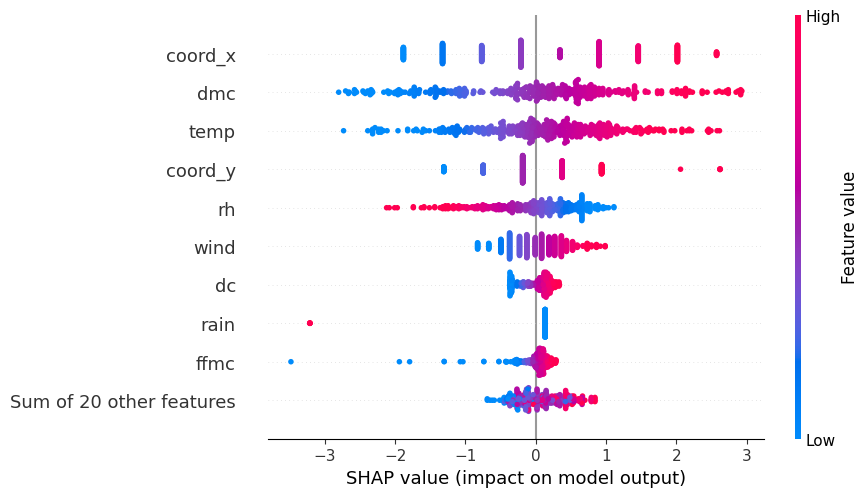

Actual area: 0.0 | Predicted: 6.94


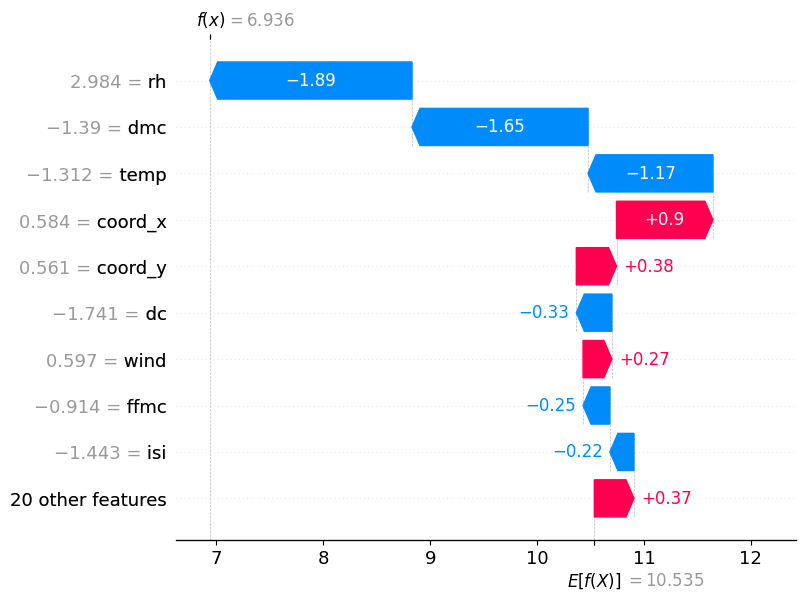

coord_x      1.106880
dmc          0.981856
temp         0.784302
coord_y      0.522426
rh           0.494917
wind         0.323293
dc           0.184279
rain         0.178568
ffmc         0.147170
isi          0.122408
day_fri      0.091786
month_aug    0.088403
day_thu      0.061959
day_sun      0.053057
day_sat      0.046585
month_mar    0.035951
month_sep    0.029312
month_jul    0.011583
day_tue      0.009749
day_mon      0.004062
month_jun    0.003121
month_oct    0.002707
day_wed      0.002312
month_apr    0.001758
month_dec    0.001517
month_feb    0.001377
month_may    0.000075
month_jan    0.000019
month_nov    0.000016
dtype: float64

In [19]:
# Complete training set
shap.plots.beeswarm(shap_train)

# Local: waterfall for one test observation
obs = 0
print('Actual area:', y_test.iloc[obs], '| Predicted:', round(best_pipe.predict(X_test.iloc[[obs]])[0], 2))
shap.plots.waterfall(shap_test[obs])

# Complete Training Set importance ranking
importance = pd.Series(np.abs(shap_train.values).mean(axis=0), index=feature_names).sort_values(ascending=False)
importance

*(Answer here.)*
+ Single Observation Explanation (Single Fire Instance)
This represents a single forest fire data point where no actual area was burned (0.0), but the machine learning model overpredicted the severity, estimating a burned area of 6.94.
+ Complete Training Set Explanation
+ Feature Removal 

## Criteria

The [rubric](./assignment_2_rubric_clean.xlsx) contains the criteria for assessment.

## Submission Information

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.

### Submission Parameters:
* Submission Due Date: `HH:MM AM/PM - DD/MM/YYYY`
* The branch name for your repo should be: `assignment-2`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_2.ipynb) should be populated and should be the only change in your pull request.
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/production/pull/<pr_id>`
    * Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.

Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.

If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at the `help` channel. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.

# Reference

Cortez,Paulo and Morais,Anbal. (2008). Forest Fires. UCI Machine Learning Repository. https://doi.org/10.24432/C5D88D.